# Simple Random Walk

This notebook introduces the mathematical and computational foundations of a simple symmetric random walk.

At each time step, the process moves:

- one unit upward with probability 0.5;
- one unit downward with probability 0.5.

The position at time \(t\) is defined as:

[ S_t = S_0 + \sum_{i=1}^{t} X_i ]

where each random variable \(X_i\) takes the value \(+1\) or \(-1\).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [2]:
SEED = 42
rng = np.random.default_rng(SEED)

In [3]:
n_steps = 100
initial_position = 0
probability_up = 0.5

steps = rng.choice(
    [-1, 1],
    size=n_steps,
    p=[1 - probability_up, probability_up]
)

steps[:10]

array([ 1, -1,  1,  1, -1,  1,  1,  1, -1, -1])

In [4]:
positions = np.concatenate(
    ([initial_position], initial_position + np.cumsum(steps))
)

positions[:10]

array([0, 1, 0, 1, 2, 1, 2, 3, 4, 3])

In [5]:
time = np.arange(n_steps + 1)

time[:10]

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [6]:
walk_data = pd.DataFrame({
    "time": time,
    "position": positions
})

walk_data.head(10)

,time,position
0,0,0
1,1,1
2,2,0
3,3,1
4,4,2
5,5,1
6,6,2
7,7,3
8,8,4
9,9,3


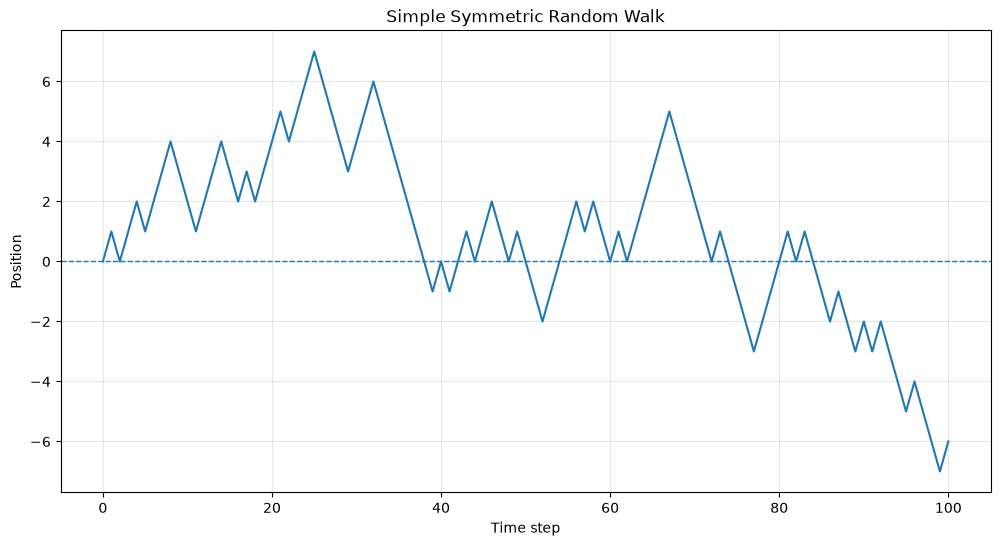

In [7]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    walk_data["time"],
    walk_data["position"],
    linewidth=1.5
)

ax.axhline(
    y=initial_position,
    linestyle="--",
    linewidth=1
)

ax.set_title("Simple Symmetric Random Walk")
ax.set_xlabel("Time step")
ax.set_ylabel("Position")
ax.grid(alpha=0.3)

plt.show()

In [8]:
walk_summary = pd.Series({
    "number_of_steps": n_steps,
    "final_position": positions[-1],
    "minimum_position": positions.min(),
    "maximum_position": positions.max(),
    "number_of_up_steps": np.sum(steps == 1),
    "number_of_down_steps": np.sum(steps == -1),
    "average_step": steps.mean()
})

walk_summary

number_of_steps         100.00
final_position           -6.00
minimum_position         -7.00
maximum_position          7.00
number_of_up_steps       47.00
number_of_down_steps     53.00
average_step             -0.06
dtype: float64

In [9]:
assert len(steps) == n_steps
assert len(positions) == n_steps + 1
assert positions[0] == initial_position
assert np.all(np.isin(steps, [-1, 1]))
assert positions[-1] == initial_position + steps.sum()

print("All consistency checks passed.")

All consistency checks passed.


## Initial observations

The simulated path fluctuates randomly around its initial position, but a single realization does not need to remain close to zero.

For a symmetric random walk:

\[
E[X_t] = 0
\]

and therefore:

\[
E[S_t] = S_0
\]

However, the variance grows with time:

\[
\operatorname{Var}(S_t) = t
\]

This means that the range of plausible positions becomes wider as the number of steps increases. To verify these theoretical properties empirically, it is necessary to simulate many independent random walks.

In [10]:
n_simulations = 10_000

all_steps = rng.choice(
    [-1, 1],
    size=(n_simulations, n_steps),
    p=[1 - probability_up, probability_up]
)

all_positions = np.concatenate(
    [
        np.full((n_simulations, 1), initial_position),
        initial_position + np.cumsum(all_steps, axis=1)
    ],
    axis=1
)

all_positions.shape

(10000, 101)

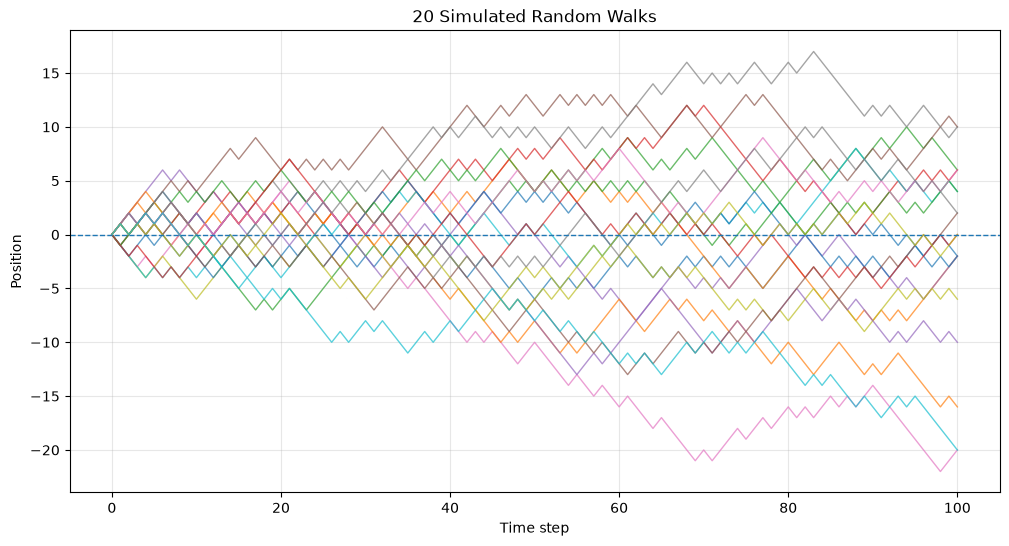

In [11]:
n_paths_to_plot = 20

fig, ax = plt.subplots(figsize=(12, 6))

for i in range(n_paths_to_plot):
    ax.plot(time, all_positions[i], linewidth=1, alpha=0.7)

ax.axhline(
    y=initial_position,
    linestyle="--",
    linewidth=1
)

ax.set_title(f"{n_paths_to_plot} Simulated Random Walks")
ax.set_xlabel("Time step")
ax.set_ylabel("Position")
ax.grid(alpha=0.3)

plt.show()

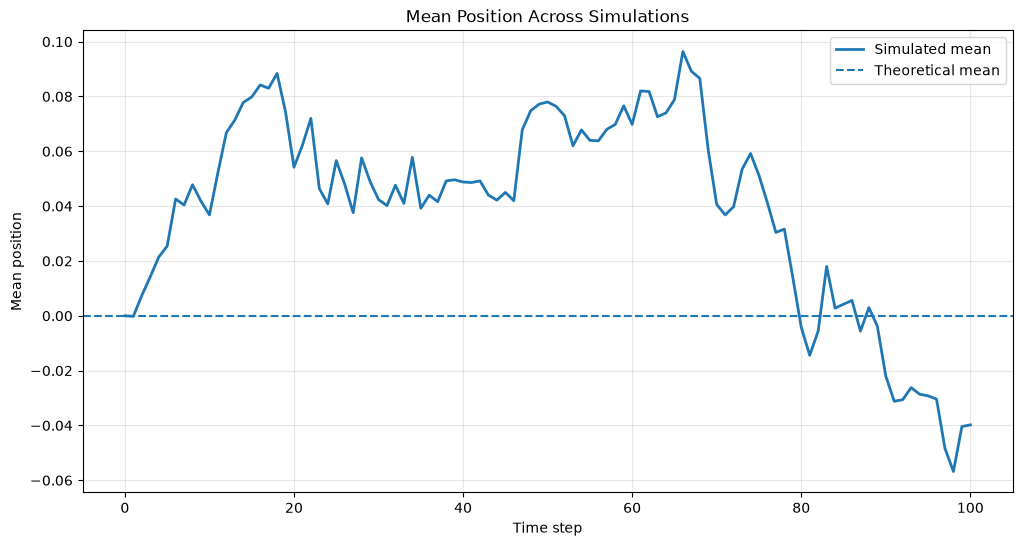

In [12]:
mean_position = all_positions.mean(axis=0)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    time,
    mean_position,
    label="Simulated mean",
    linewidth=2
)

ax.axhline(
    y=initial_position,
    linestyle="--",
    label="Theoretical mean"
)

ax.set_title("Mean Position Across Simulations")
ax.set_xlabel("Time step")
ax.set_ylabel("Mean position")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

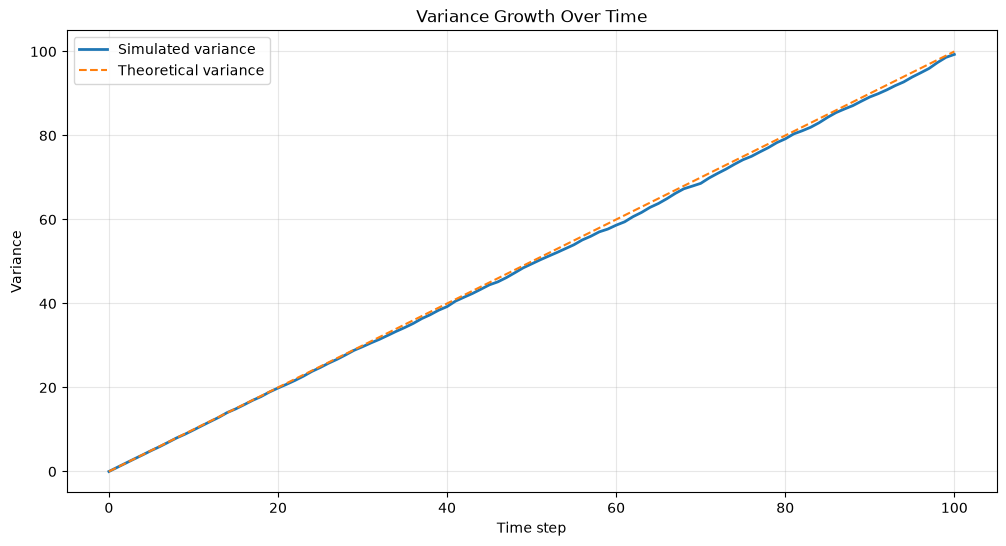

In [13]:
simulated_variance = all_positions.var(axis=0)
theoretical_variance = time.astype(float)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    time,
    simulated_variance,
    label="Simulated variance",
    linewidth=2
)

ax.plot(
    time,
    theoretical_variance,
    linestyle="--",
    label="Theoretical variance"
)

ax.set_title("Variance Growth Over Time")
ax.set_xlabel("Time step")
ax.set_ylabel("Variance")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

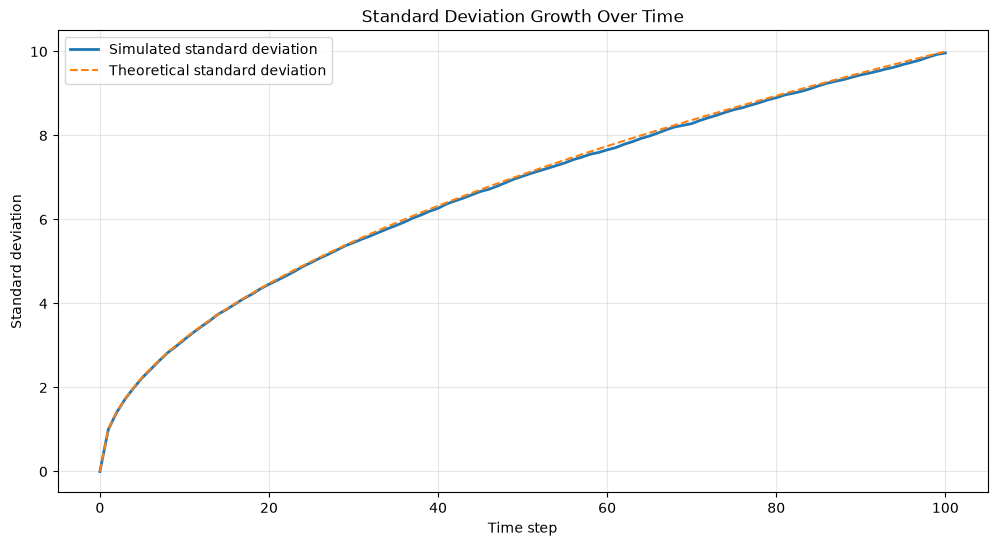

In [14]:
simulated_std = all_positions.std(axis=0)
theoretical_std = np.sqrt(time)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    time,
    simulated_std,
    label="Simulated standard deviation",
    linewidth=2
)

ax.plot(
    time,
    theoretical_std,
    linestyle="--",
    label="Theoretical standard deviation"
)

ax.set_title("Standard Deviation Growth Over Time")
ax.set_xlabel("Time step")
ax.set_ylabel("Standard deviation")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

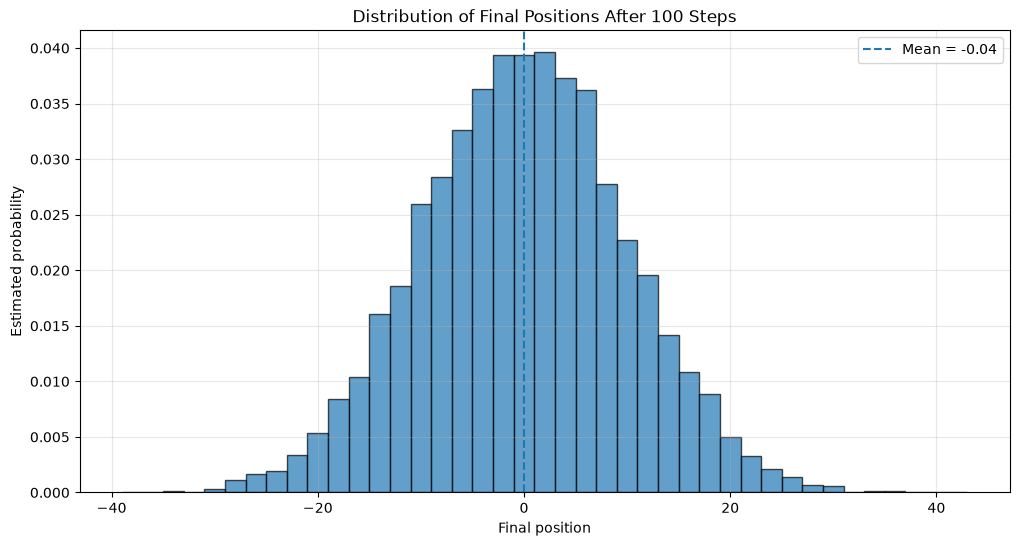

In [15]:
final_positions = all_positions[:, -1]

fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    final_positions,
    bins=np.arange(
        final_positions.min() - 1,
        final_positions.max() + 2,
        2
    ),
    density=True,
    edgecolor="black",
    alpha=0.7
)

ax.axvline(
    final_positions.mean(),
    linestyle="--",
    label=f"Mean = {final_positions.mean():.2f}"
)

ax.set_title(f"Distribution of Final Positions After {n_steps} Steps")
ax.set_xlabel("Final position")
ax.set_ylabel("Estimated probability")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

In [16]:
comparison = pd.Series({
    "simulated_final_mean": final_positions.mean(),
    "theoretical_final_mean": initial_position,
    "simulated_final_variance": final_positions.var(),
    "theoretical_final_variance": n_steps,
    "simulated_final_std": final_positions.std(),
    "theoretical_final_std": np.sqrt(n_steps)
})

comparison

simulated_final_mean           -0.039800
theoretical_final_mean          0.000000
simulated_final_variance       99.306016
theoretical_final_variance    100.000000
simulated_final_std             9.965240
theoretical_final_std          10.000000
dtype: float64

In [17]:
probability_positive = np.mean(final_positions > 0)
probability_negative = np.mean(final_positions < 0)
probability_zero = np.mean(final_positions == 0)

pd.Series({
    "P(final position > 0)": probability_positive,
    "P(final position < 0)": probability_negative,
    "P(final position = 0)": probability_zero
})

P(final position > 0)    0.4611
P(final position < 0)    0.4602
P(final position = 0)    0.0787
dtype: float64

In [18]:
assert all_steps.shape == (n_simulations, n_steps)
assert all_positions.shape == (n_simulations, n_steps + 1)
assert np.all(all_positions[:, 0] == initial_position)
assert np.all(np.isin(all_steps, [-1, 1]))

print("Monte Carlo simulation checks passed.")

Monte Carlo simulation checks passed.


## Monte Carlo results

The simulation confirms the main theoretical properties of the symmetric random walk.

Across many independent paths, the average position remains close to the initial position:

\[
E[S_t] = S_0
\]

The variance grows approximately linearly with time:

\[
\operatorname{Var}(S_t) = t
\]

while the standard deviation grows proportionally to the square root of time:

\[
\operatorname{Std}(S_t) = \sqrt{t}
\]

Although the expected position remains constant, uncertainty increases as the time horizon becomes longer. Individual paths can therefore move far away from the starting point even when the process has no upward or downward drift.